# Étape 13 : régression logistique vs LightGBM, en validation croisée sans fuite

L'étape 11 voulait **expliquer** (quels facteurs comptent, à valeur égale des autres).
Ici on veut **prédire** : à la minute 15, quelle probabilité de victoire donner au bleu,
sur des parties que le modèle n'a jamais vues ?

Deux modèles :
- **Régression logistique** : une somme pondérée des variables passée dans une courbe en S.
  Simple, stable, lisible. Elle ne voit une interaction (ex. or × scaling) que si on la lui donne.
- **LightGBM** : des centaines de petits arbres de décision, chacun corrige les erreurs des
  précédents (*gradient boosting*). Il trouve seul les effets non linéaires et les interactions,
  mais il lui faut beaucoup de données pour ne pas apprendre le bruit.

Et une question : **le score de scaling des compositions (étape 12) aide-t-il à prédire ?**

Deux règles pour que la comparaison soit honnête :
1. **Pas de fuite** : tout ce qui est appris (notes de scaling, moyennes du StandardScaler,
   modèle) l'est sur la partie entraînement seulement, dans chaque pli.
2. **Respect du temps** : on valide toujours sur des parties plus récentes que celles
   de l'entraînement, comme en vrai (on prédit les parties de demain).

Critère principal : la **log loss** (plus bas = mieux). Elle juge la qualité des probabilités :
annoncer 90 % et perdre coûte très cher, annoncer 55 % et perdre coûte peu.
La précision (% de bons pronostics) ne voit pas la différence entre 51 % et 99 %.

Plan :
1. Connexion et outils
2. Données et test mis sous clé
3. La validation croisée chronologique
4. Régler LightGBM
5. Comparaison en validation croisée
6. Deux fuites possibles avec le score de scaling
7. Le test final (une seule fois)
8. Ce que les modèles utilisent
9. Conclusions

## 1. Connexion et outils

Avant de lancer : Docker Desktop ouvert et `docker compose start` fait.

Le code réutilisable est dans deux modules de `src/` :
- `features.py` (étape 12) : construit le jeu de données et le score de scaling ;
- `models.py` (nouveau) : les modèles, la préparation sans fuite, la validation croisée,
  les métriques et le bootstrap apparié. Les étapes 14 (calibration, SHAP) et l'appli
  Streamlit s'en serviront aussi : c'est pour ça qu'il n'est pas écrit dans le notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook tourne depuis notebooks/ : on ajoute src/ au chemin des imports.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from features import (FEATURES, ROLE_FEATURES, SCALING_FEATURES, TARGET,
                      add_scaling, build_features, fit_scaling, time_split)
from models import (cross_validate, evaluate, fit_predict, make_baseline, make_lgbm,
                    make_logit, paired_bootstrap, time_folds)

warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## 2. Données et test mis sous clé

On reprend le jeu de l'étape 12 : une ligne par partie vue du bleu, écarts bleu − rouge
à la minute 15. Les **20 % de parties les plus récentes** forment le **test**. On n'y touche
plus avant la partie 7 : tous les choix (réglages, variables) se font sur les 80 % restants.
Sinon on choisirait le modèle qui a eu de la chance sur le test, et son score serait trop beau.

In [2]:
df = build_features()
train, test = time_split(df, test_frac=0.2)

print(f"{len(df)} parties : {len(train)} pour choisir (entraînement), {len(test)} en test.")
print(f"Entraînement : {train['game_creation'].min():%d/%m} au {train['game_creation'].max():%d/%m}, "
      f"bleu {train[TARGET].mean():.1%}")
print(f"Test         : {test['game_creation'].min():%d/%m} au {test['game_creation'].max():%d/%m}, "
      f"bleu {test[TARGET].mean():.1%}")

4762 parties : 3809 pour choisir (entraînement), 953 en test.
Entraînement : 16/07 au 24/10, bleu 48.8%
Test         : 24/10 au 28/10, bleu 47.1%


## 3. La validation croisée chronologique

**Le principe.** Un seul découpage entraînement / validation donne un score bruité
(avec ~800 parties de validation, la log loss varie de ±0,02 selon le hasard du découpage).
La validation croisée répète l'exercice sur plusieurs découpages et fait la moyenne.

**Pourquoi `TimeSeriesSplit` et pas un `KFold` mélangé.** Avec `KFold(shuffle=True)`,
un pli entraînerait sur des parties de fin octobre pour prédire des parties de début octobre :
le modèle profiterait du futur (patchs, champions à la mode). `TimeSeriesSplit` découpe
l'entraînement en 6 blocs chronologiques : le pli 1 apprend sur le bloc 1 et valide sur le 2,
le pli 2 apprend sur les blocs 1-2 et valide sur le 3, etc. L'entraînement grandit à chaque pli.

**Ce qui est réappris dans chaque pli** (fonction `prepare` puis `fit_predict` de `models.py`) :
les notes de scaling des champions (sur l'entraînement du pli, et hors pli pour les parties
d'entraînement elles-mêmes, voir partie 6), le StandardScaler, le modèle.

In [3]:
sorted_train, folds = time_folds(train, n_splits=5)
fold_table = pd.DataFrame([
    {"pli": k, "parties d'entraînement": len(tr), "parties de validation": len(va),
     "validation du": f"{sorted_train['game_creation'].iloc[va[0]]:%d/%m}",
     "au": f"{sorted_train['game_creation'].iloc[va[-1]]:%d/%m}"}
    for k, (tr, va) in enumerate(folds, start=1)
])
fold_table

,pli,parties d'entraînement,parties de validation,validation du,au
0,1,639,634,10/08,28/08
1,2,1273,634,28/08,25/09
2,3,1907,634,25/09,11/10
3,4,2541,634,11/10,19/10
4,5,3175,634,19/10,24/10


**Les modèles comparés** (une ligne = un modèle et ses variables) :

| Nom | Modèle | Variables |
|---|---|---|
| Constante | toujours le taux du bleu | aucune |
| Logit or seul | régression logistique | `gold_k` |
| Logit | régression logistique | les 11 écarts de `FEATURES` |
| Logit + scaling | régression logistique | 11 écarts + `scaling_diff` + `gold_x_scaling` |
| LightGBM | LightGBM | 11 écarts + or par poste |
| LightGBM + scaling | LightGBM | idem + `scaling_diff` |

Pourquoi des variables différentes selon le modèle :
- l'**or par poste** additionne exactement `gold_k` : en logistique, ce serait une
  colinéarité parfaite ; un arbre, lui, choisit simplement la variable la plus utile à chaque coupure ;
- `gold_x_scaling` est donné à la logistique parce qu'elle ne sait pas inventer
  une interaction ; LightGBM la trouve seul en coupant sur l'or puis sur le scaling.

La « Constante » et « Logit or seul » sont des **références** : un modèle compliqué
qui ne bat pas « Logit or seul » ne sert à rien.

In [4]:
LOGIT_COLS = FEATURES
LOGIT_SCALING_COLS = FEATURES + SCALING_FEATURES
LGBM_COLS = FEATURES + ROLE_FEATURES
LGBM_SCALING_COLS = LGBM_COLS + ["scaling_diff"]

# nom -> (fabrique de modèle, variables, avec score de scaling ?)
# LightGBM est ajouté après son réglage (partie 4).
variants = {
    "Constante":       (make_baseline, ["gold_k"], False),  # la colonne est ignorée
    "Logit or seul":   (make_logit, ["gold_k"], False),
    "Logit":           (make_logit, LOGIT_COLS, False),
    "Logit + scaling": (make_logit, LOGIT_SCALING_COLS, True),
}

## 4. Régler LightGBM

LightGBM a des réglages (*hyperparamètres*) qu'il faut choisir. On teste une petite grille,
**en validation croisée sur l'entraînement** (jamais sur le test) :
- `num_leaves` : taille de chaque arbre (4 feuilles = arbres très simples, 15 = plus fins) ;
- `n_estimators` : nombre d'arbres (avec un taux d'apprentissage de 0,03, chaque arbre
  corrige un peu les précédents : trop d'arbres = le modèle finit par apprendre le bruit).

Pourquoi une petite grille : avec ~3 800 parties, chaque essai de plus augmente la chance
de choisir un réglage qui a seulement eu de la chance sur ces plis. 9 essais suffisent
pour voir la tendance. Si le meilleur réglage est au bord de la grille (4 feuilles ou
100 arbres), c'est le signe que des modèles encore plus simples pourraient faire mieux. (Les réglages fixes, comme 50 parties minimum par feuille,
sont expliqués dans `make_lgbm`.)

Ça prend environ une minute.

In [5]:
grid = []
for num_leaves in [4, 7, 15]:
    for n_estimators in [100, 200, 400]:
        make = lambda nl=num_leaves, ne=n_estimators: make_lgbm(n_estimators=ne, num_leaves=nl)
        cv = cross_validate(make, LGBM_COLS, train)
        grid.append({"num_leaves": num_leaves, "n_estimators": n_estimators,
                     "log_loss": cv["log_loss"].mean(), "auc": cv["auc"].mean()})
grid = pd.DataFrame(grid).sort_values("log_loss")
best = grid.iloc[0]
print(f"Meilleur réglage : num_leaves={int(best.num_leaves)}, n_estimators={int(best.n_estimators)}")
grid.round(4)

Meilleur réglage : num_leaves=4, n_estimators=200


,num_leaves,n_estimators,log_loss,auc
1,4,200,0.5353,0.8048
0,4,100,0.5373,0.8044
3,7,100,0.5381,0.8022
6,15,100,0.5390,0.8009
2,4,400,0.5396,0.8021
4,7,200,0.5406,0.8006
7,15,200,0.5462,0.7969
5,7,400,0.5524,0.7943
8,15,400,0.5684,0.7868


In [6]:
BEST = {"num_leaves": int(best.num_leaves), "n_estimators": int(best.n_estimators)}
make_lgbm_best = lambda: make_lgbm(**BEST)

variants["LightGBM"] = (make_lgbm_best, LGBM_COLS, False)
variants["LightGBM + scaling"] = (make_lgbm_best, LGBM_SCALING_COLS, True)

## 5. Comparaison en validation croisée

Chaque modèle passe par les mêmes 5 plis. Pour chaque score : la moyenne sur les plis
et l'écart type (combien il varie d'un pli à l'autre).

In [7]:
cv_results = {name: cross_validate(make, cols, train, use_scaling=sc)
              for name, (make, cols, sc) in variants.items()}

summary = pd.DataFrame({
    name: {"log_loss": r["log_loss"].mean(), "± (écart type)": r["log_loss"].std(),
           "brier": r["brier"].mean(), "auc": r["auc"].mean(), "accuracy": r["accuracy"].mean()}
    for name, r in cv_results.items()
}).T
summary.round(4)

,log_loss,± (écart type),brier,auc,accuracy
Constante,0.6930,0.0007,0.2499,0.5000,0.5126
Logit or seul,0.5355,0.0162,0.1817,0.8005,0.7151
Logit,0.5297,0.0244,0.1792,0.8075,0.7259
Logit + scaling,0.5295,0.0227,0.1787,0.8090,0.7271
LightGBM,0.5353,0.0168,0.1808,0.8048,0.7221
LightGBM + scaling,0.5350,0.0153,0.1807,0.8051,0.7221


**Comparer pli par pli.** L'écart type ci-dessus mélange deux choses : la difficulté du pli
(certains plis sont plus durs pour TOUS les modèles) et l'écart entre modèles. Comme tous les
modèles voient les mêmes plis, on regarde plutôt la **différence pli par pli** : si un modèle
est meilleur sur 5 plis sur 5, c'est plus parlant qu'une moyenne un peu plus basse.

In [8]:
def paired(a, b):
    """Différence de log loss b − a pli par pli (négatif = b meilleur)."""
    d = cv_results[b]["log_loss"] - cv_results[a]["log_loss"]
    return {"écart moyen": d.mean(), "plis où b gagne": f"{(d < 0).sum()} / {len(d)}",
            **{f"pli {k}": v for k, v in enumerate(d, start=1)}}

comparisons = {
    "Logit vs Logit or seul":          paired("Logit or seul", "Logit"),
    "Logit + scaling vs Logit":        paired("Logit", "Logit + scaling"),
    "LightGBM vs Logit":               paired("Logit", "LightGBM"),
    "LightGBM + scaling vs LightGBM":  paired("LightGBM", "LightGBM + scaling"),
}
pd.DataFrame(comparisons).T

,écart moyen,plis où b gagne,pli 1,pli 2,pli 3,pli 4,pli 5
Logit vs Logit or seul,-0.005787,3 / 5,-0.004763,-0.017604,0.003469,0.00011,-0.010146
Logit + scaling vs Logit,-0.000146,3 / 5,0.005807,0.00143,-0.003507,-0.002708,-0.001753
LightGBM vs Logit,0.005626,2 / 5,0.009685,0.015293,-0.00316,-0.003541,0.009853
LightGBM + scaling vs LightGBM,-0.00034,3 / 5,0.004971,0.002117,-0.003054,-0.004253,-0.00148


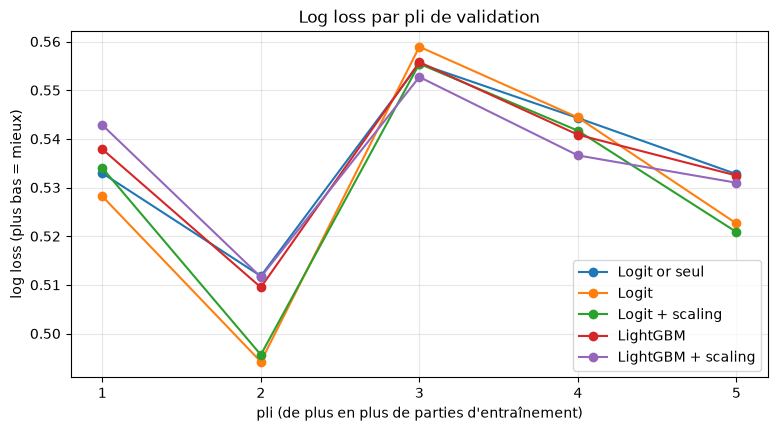

In [9]:
fig, ax = plt.subplots()
for name, r in cv_results.items():
    if name == "Constante":
        continue
    ax.plot(r["fold"], r["log_loss"], marker="o", label=name)
ax.set(xlabel="pli (de plus en plus de parties d'entraînement)", ylabel="log loss (plus bas = mieux)",
       title="Log loss par pli de validation", xticks=range(1, 6))
ax.legend()
plt.show()

## 6. Deux fuites possibles avec le score de scaling

Le score de scaling est fabriqué avec des **résultats de parties** (des taux de victoire).
Il peut donc faire fuiter la réponse de deux façons.

**Fuite 1, la grosse : apprendre les notes avec les parties de validation.** On apprend les
notes une seule fois sur tout l'entraînement, avant la validation croisée. Dans chaque pli,
les parties de validation ont servi à fabriquer les notes : leur score « connaît » leur résultat.

**Fuite 2, la discrète : appliquer les notes aux parties qui ont servi à les apprendre.**
Même sans toucher à la validation, si le score des parties d'*entraînement* est calculé avec
des notes apprises sur ces mêmes parties, chaque partie a un peu contribué à la note de ses
propres champions. Le modèle voit un score plus fiable qu'il ne l'est en vrai, et lui donne
trop de poids. C'est le piège classique du *target encoding*. La parade (`oof_scaling` dans
`models.py`) : calculer le score des parties d'entraînement **hors pli**, avec des notes
apprises sur les autres parties de l'entraînement. C'est le réglage utilisé partout
dans ce notebook (parties 5 et 7).

Le tableau compare, pour « Logit + scaling » : la version propre (hors pli), la version
naïve (fuite 2) et la version avec fuite 1.

In [10]:
cv_naive = cross_validate(make_logit, LOGIT_SCALING_COLS, train, use_scaling=True, oof=False)
leaky_train = add_scaling(train, fit_scaling(train))   # notes apprises sur TOUT l'entraînement
cv_leak = cross_validate(make_logit, LOGIT_SCALING_COLS, leaky_train, use_scaling=False)

leak_table = pd.DataFrame({
    "Logit (sans scaling)": cv_results["Logit"][["log_loss", "auc"]].mean(),
    "Logit + scaling, propre (hors pli)": cv_results["Logit + scaling"][["log_loss", "auc"]].mean(),
    "Logit + scaling, naïf (fuite 2)": cv_naive[["log_loss", "auc"]].mean(),
    "Logit + scaling, AVEC FUITE 1": cv_leak[["log_loss", "auc"]].mean(),
}).T
leak_table.round(4)

,log_loss,auc
Logit (sans scaling),0.5297,0.8075
"Logit + scaling, propre (hors pli)",0.5295,0.8090
"Logit + scaling, naïf (fuite 2)",0.5346,0.8079
"Logit + scaling, AVEC FUITE 1",0.5242,0.8149


## 7. Le test final (une seule fois)

Les choix sont faits (réglages de LightGBM, liste des modèles). On réentraîne chaque modèle
sur **tout l'entraînement** (notes de scaling réapprises sur tout l'entraînement) et on prédit
les parties du test, jamais vues.

Pour savoir si un écart entre deux modèles est réel ou dû au hasard des parties du test,
on utilise un **bootstrap apparié** (`paired_bootstrap`) : on retire 2 000 fois les parties du
test avec remise, et on recalcule à chaque fois l'écart de log loss **sur les mêmes parties
pour les deux modèles**. L'intervalle à 95 % de ces 2 000 écarts : s'il contient 0,
on ne peut pas dire qu'un modèle est meilleur.

In [11]:
test_pred, fitted = {}, {}
for name, (make, cols, sc) in variants.items():
    test_pred[name], fitted[name] = fit_predict(make, cols, train, test, use_scaling=sc)

test_summary = pd.DataFrame({name: evaluate(test[TARGET], p) for name, p in test_pred.items()}).T
test_summary.round(4)

,log_loss,brier,auc,accuracy
Constante,0.6921,0.2495,0.5000,0.5289
Logit or seul,0.5391,0.1819,0.7994,0.7251
Logit,0.5242,0.1752,0.8134,0.7408
Logit + scaling,0.5265,0.1760,0.8117,0.7440
LightGBM,0.5284,0.1772,0.8091,0.7303
LightGBM + scaling,0.5299,0.1777,0.8084,0.7335


In [12]:
y_test = test[TARGET].to_numpy()
pairs = [("Logit or seul", "Logit"), ("Logit", "Logit + scaling"),
         ("Logit", "LightGBM"), ("LightGBM", "LightGBM + scaling")]
boot = []
for a, b in pairs:
    diff, low, high = paired_bootstrap(y_test, test_pred[a], test_pred[b])
    verdict = "b meilleur" if high < 0 else ("a meilleur" if low > 0 else "pas de différence nette")
    boot.append({"a": a, "b": b, "log loss b − a": diff, "IC 95 % bas": low,
                 "IC 95 % haut": high, "verdict": verdict})
pd.DataFrame(boot).round(4)

,a,b,log loss b − a,IC 95 % bas,IC 95 % haut,verdict
0,Logit or seul,Logit,-0.0150,-0.0259,-0.0052,b meilleur
1,Logit,Logit + scaling,0.0024,-0.0027,0.0075,pas de différence nette
2,Logit,LightGBM,0.0042,-0.0027,0.0106,pas de différence nette
3,LightGBM,LightGBM + scaling,0.0015,-0.0030,0.0062,pas de différence nette


**Les probabilités des deux modèles se ressemblent-elles ?** Chaque point est une partie
du test : probabilité donnée par la logistique (x) et par LightGBM (y). Sur la diagonale,
les deux modèles sont d'accord. (La calibration, c'est-à-dire « quand le modèle dit 70 %,
le bleu gagne-t-il 70 % du temps ? », sera l'étape 14.)

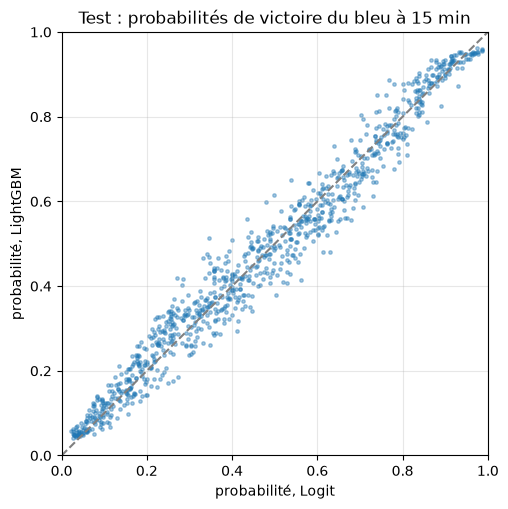

Corrélation 0.985 ; écart moyen 3.6% ; parties où les deux modèles diffèrent de plus de 10 points : 3.9%


In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(test_pred["Logit"], test_pred["LightGBM"], s=6, alpha=0.4)
ax.plot([0, 1], [0, 1], color="grey", linestyle="--")
ax.set(xlabel="probabilité, Logit", ylabel="probabilité, LightGBM",
       title="Test : probabilités de victoire du bleu à 15 min", xlim=(0, 1), ylim=(0, 1))
plt.show()
corr = np.corrcoef(test_pred["Logit"], test_pred["LightGBM"])[0, 1]
gap = np.abs(test_pred["Logit"] - test_pred["LightGBM"])
print(f"Corrélation {corr:.3f} ; écart moyen {gap.mean():.1%} ; "
      f"parties où les deux modèles diffèrent de plus de 10 points : {(gap > 0.10).mean():.1%}")

## 8. Ce que les modèles utilisent

Un premier coup d'œil (l'étape 14 le fera proprement avec SHAP) :
- **Logistique** : coefficients sur variables centrées-réduites, donc comparables entre eux
  (« effet d'un écart type de plus »). Ils diffèrent des odds ratios de l'étape 11 (pénalité
  L2, variables à l'échelle), mais l'ordre doit être proche.
- **LightGBM** : importance « gain » = de combien chaque variable a fait baisser l'erreur,
  au total, dans toutes les coupures où elle sert.

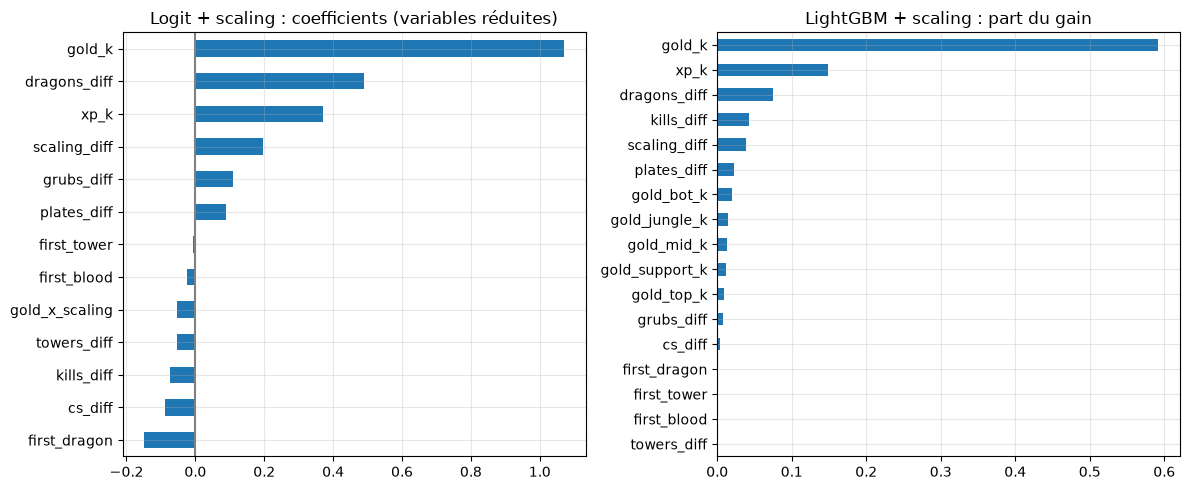

In [14]:
logit = fitted["Logit + scaling"][-1]          # le LogisticRegression au bout du pipeline
coefs = pd.Series(logit.coef_[0], index=LOGIT_SCALING_COLS).sort_values()

lgbm = fitted["LightGBM + scaling"]
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=LGBM_SCALING_COLS)
gain = (gain / gain.sum()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
coefs.plot.barh(ax=axes[0], title="Logit + scaling : coefficients (variables réduites)")
axes[0].axvline(0, color="grey")
gain.plot.barh(ax=axes[1], title="LightGBM + scaling : part du gain")
plt.tight_layout()
plt.show()

## 9. Conclusions

Résultats sur 4 762 parties (patchs 16.14 à 16.21) : 3 809 pour choisir (validation croisée chronologique en 5 plis), 953 parties les plus récentes en test, regardées une seule fois.

**1. La régression logistique est le meilleur modèle.** Sur le test : log loss 0,524, AUC 0,813, 74,1 % de bons pronostics (la constante est à 0,692). LightGBM fait 0,528 (AUC 0,809) : l'écart avec la logistique n'est pas significatif (bootstrap apparié : +0,004, IC 95 % −0,003 à +0,011). En validation croisée, LightGBM est derrière sur 3 plis sur 5 (0,535 contre 0,530).

**2. Pourquoi LightGBM ne gagne pas.** Le signal est surtout linéaire et porté par l'or : l'or à lui seul donne déjà 0,539 sur le test. Le meilleur réglage de LightGBM est le plus simple de la grille (4 feuilles, 200 arbres), et les arbres plus gros font moins bien (0,568 avec 15 feuilles et 400 arbres) : avec ~3 800 parties, la complexité supplémentaire apprend surtout du bruit. Les deux modèles donnent presque les mêmes probabilités (corrélation 0,985, écart moyen 3,6 points).

**3. Les 11 variables apportent quelque chose au-delà de l'or.** Logit contre Logit or seul : −0,015 de log loss sur le test, IC 95 % −0,026 à −0,005. Les poids confirment l'étape 11 : or, puis dragons, puis XP ; kills, tours, CS et premiers objectifs n'ajoutent rien une fois l'or connu.

**4. Le score de scaling n'améliore pas la prédiction à 15 min.** Calculé proprement, il ne change rien : −0,0001 en validation croisée, +0,002 sur le test (IC 95 % −0,003 à +0,008), pareil pour LightGBM. L'interaction or × scaling est faible (coefficient −0,05 en variables réduites). Une composition qui « scale » se lit peut-être déjà dans l'état de la partie à 15 min, ou l'effet est trop faible pour ~4 800 parties.

**5. Les deux fuites, mesurées.**
- *Fuite 1* (notes apprises avec les parties de validation) : log loss 0,524 au lieu de 0,530. Elle ferait croire, à tort, que le scaling améliore le modèle.
- *Fuite 2* (notes appliquées aux parties qui ont servi à les apprendre) : 0,535 au lieu de 0,530. Ici l'effet est inverse : le modèle surestime la fiabilité du score (coefficient 0,31 au lieu de 0,20) et prédit moins bien. Le calcul hors pli (`oof_scaling`) corrige le problème.
Une fuite peut donc rendre un modèle trop beau ou trop mauvais : dans les deux cas, la conclusion serait fausse.

**Décision pour la suite.** Modèle retenu : régression logistique sur les 11 variables, sans score de scaling (aussi bon, plus simple). LightGBM reste la référence pour comparer le GRU en janvier. L'étape 14 vérifiera la calibration (Brier, courbe de fiabilité) et expliquera les prédictions avec SHAP.

**Limites.** Une seule saison de patchs (juillet à octobre), test court (5 jours, 953 parties) : les intervalles restent larges, de l'ordre de ±0,005 de log loss. Pli 1 entraîné sur 639 parties seulement, donc plus bruité.
